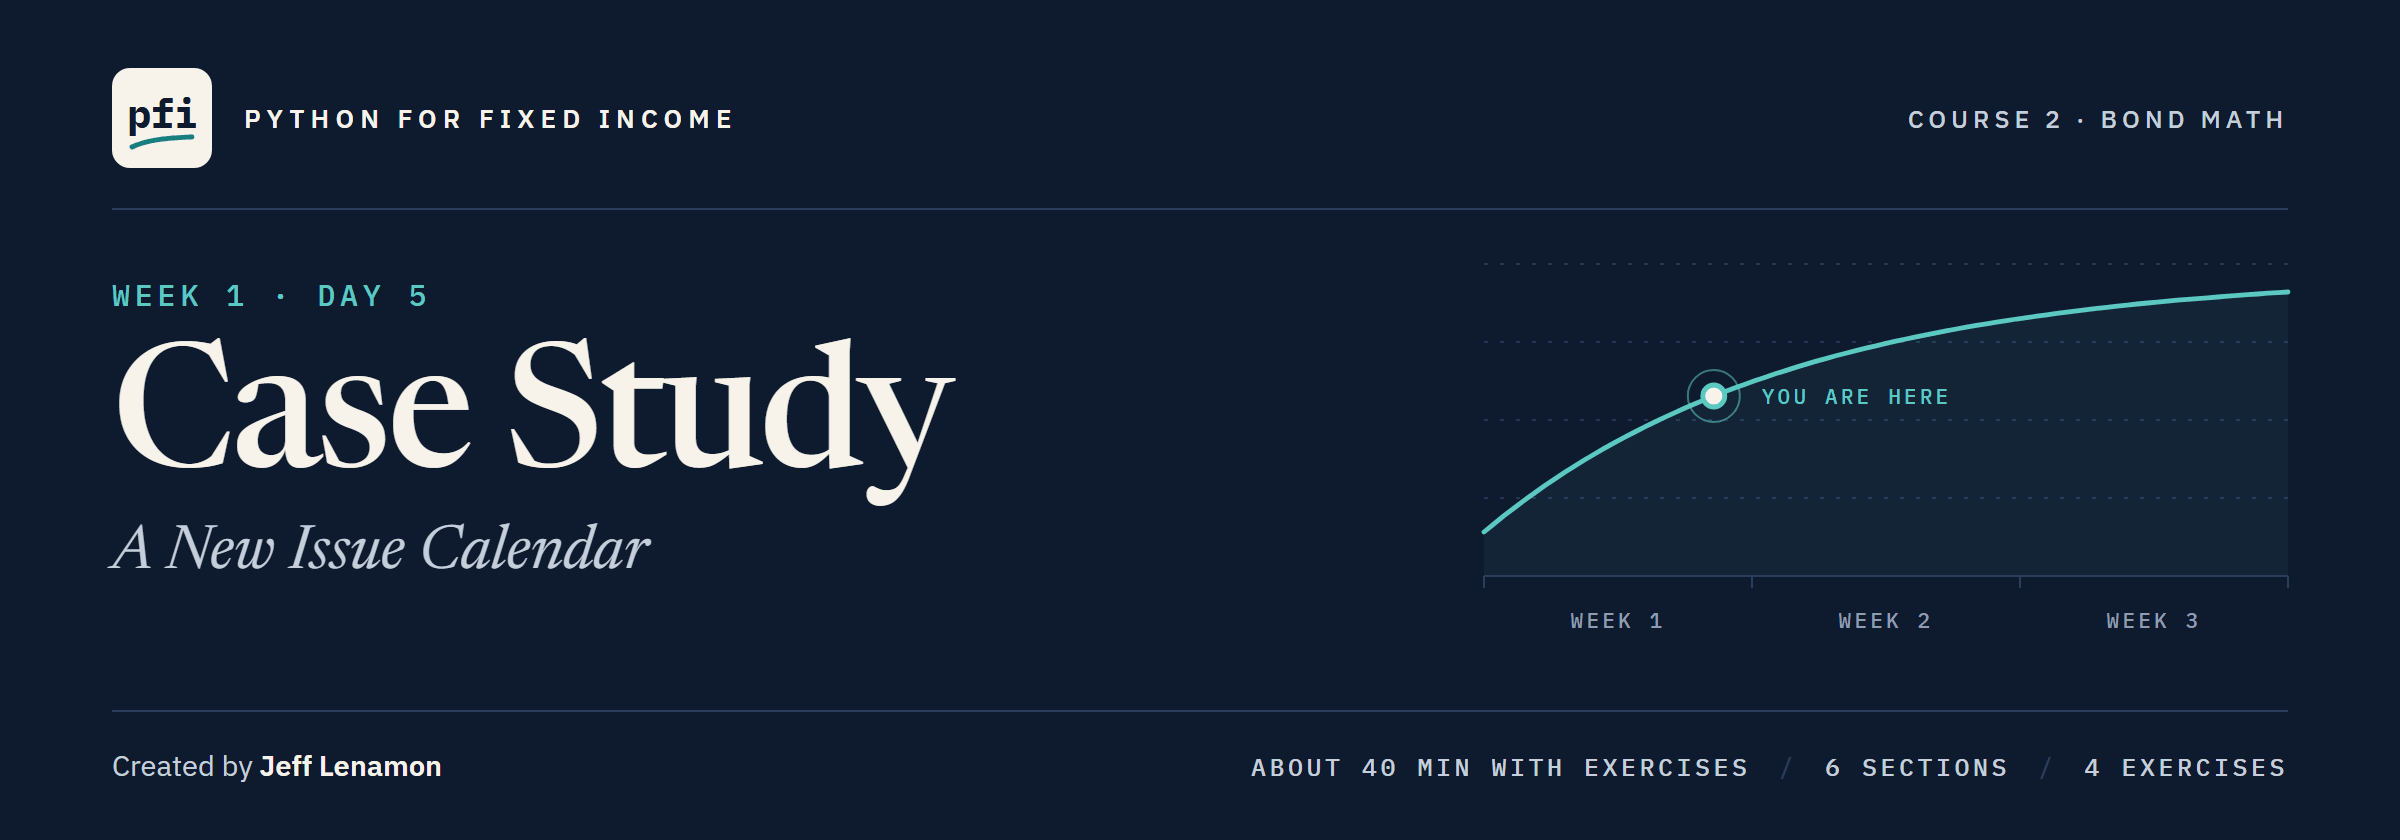

# Case Study: A New Issue Calendar

Week 1, Day 5. Eight new issues described with the week's two pricing functions, every number tied to Excel, and sent as a workbook Excel calculates itself.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week1/day5/05_case_study_a_new_issue_calendar.ipynb)

## Problem Definition

### Context

The desk lead's fifth note:

> Eight new issues price today, all settling on 30 September 2026. Before the calendar goes round: what does each yield at its re-offer price? Price all eight at one yield, so coupon and term compare on equal terms. On the grid of eighths, which coupon would price each one nearest par at its own yield, and what is one eighth of coupon worth in price? Last, send it as a workbook whose yields and prices Excel works out itself. Describe the calendar: no view on any issue.

The re-offer price is the price the new bonds are sold at.
Each bond settles on its issue date, so nothing has accrued and notebook 02's coupon-date pricing applies exactly.

### Objective

You are the desk's analyst: answer the five asks with your module, and tie every number to Excel.

### The Data

<table align="left">
<tr><th align="left">CUSIP</th><th align="left">Issuer</th><th align="left">Rating</th><th align="left">Coupon (%)</th><th align="left">Years</th><th align="left">Maturity</th><th align="left">Re-offer price</th></tr>
<tr><td align="left">99010KZA6</td><td align="left">Thalostrin Finance</td><td align="left">BBB+</td><td align="left">5.125</td><td align="left">5</td><td align="left">2031-09-30</td><td align="left">99.874</td></tr>
<tr><td align="left">99011LZA3</td><td align="left">Galvostrin Resources</td><td align="left">BBB+</td><td align="left">5.625</td><td align="left">10</td><td align="left">2036-09-30</td><td align="left">99.512</td></tr>
<tr><td align="left">99012MZA0</td><td align="left">Hulvimer Pipeline</td><td align="left">BBB</td><td align="left">5.5</td><td align="left">7</td><td align="left">2033-09-30</td><td align="left">99.760</td></tr>
<tr><td align="left">99013NZA7</td><td align="left">Kezerone Paper</td><td align="left">A-</td><td align="left">4.625</td><td align="left">3</td><td align="left">2029-09-30</td><td align="left">99.942</td></tr>
<tr><td align="left">99014OZA4</td><td align="left">Elvorin Medical</td><td align="left">BB-</td><td align="left">7.875</td><td align="left">8</td><td align="left">2034-09-30</td><td align="left">100.000</td></tr>
<tr><td align="left">99016QZA7</td><td align="left">Corvolvey Systems</td><td align="left">BB+</td><td align="left">7</td><td align="left">5</td><td align="left">2031-09-30</td><td align="left">99.000</td></tr>
<tr><td align="left">99017RZA4</td><td align="left">Rulvolvey Industrial</td><td align="left">BBB-</td><td align="left">6</td><td align="left">30</td><td align="left">2056-09-30</td><td align="left">98.975</td></tr>
<tr><td align="left">99020UZA2</td><td align="left">Morvithe Logistics</td><td align="left">B</td><td align="left">8.75</td><td align="left">6</td><td align="left">2032-09-30</td><td align="left">98.500</td></tr>
</table>
<br clear="left">

Invented issuers and CUSIPs: fixed-rate bullets, coupons twice a year, 30/360.

### How We Will Work

Six Predicts on the way: decide before you run the cell.

**Eight prices in; a workbook Excel calculates out.**

## Your Route Through Day 5

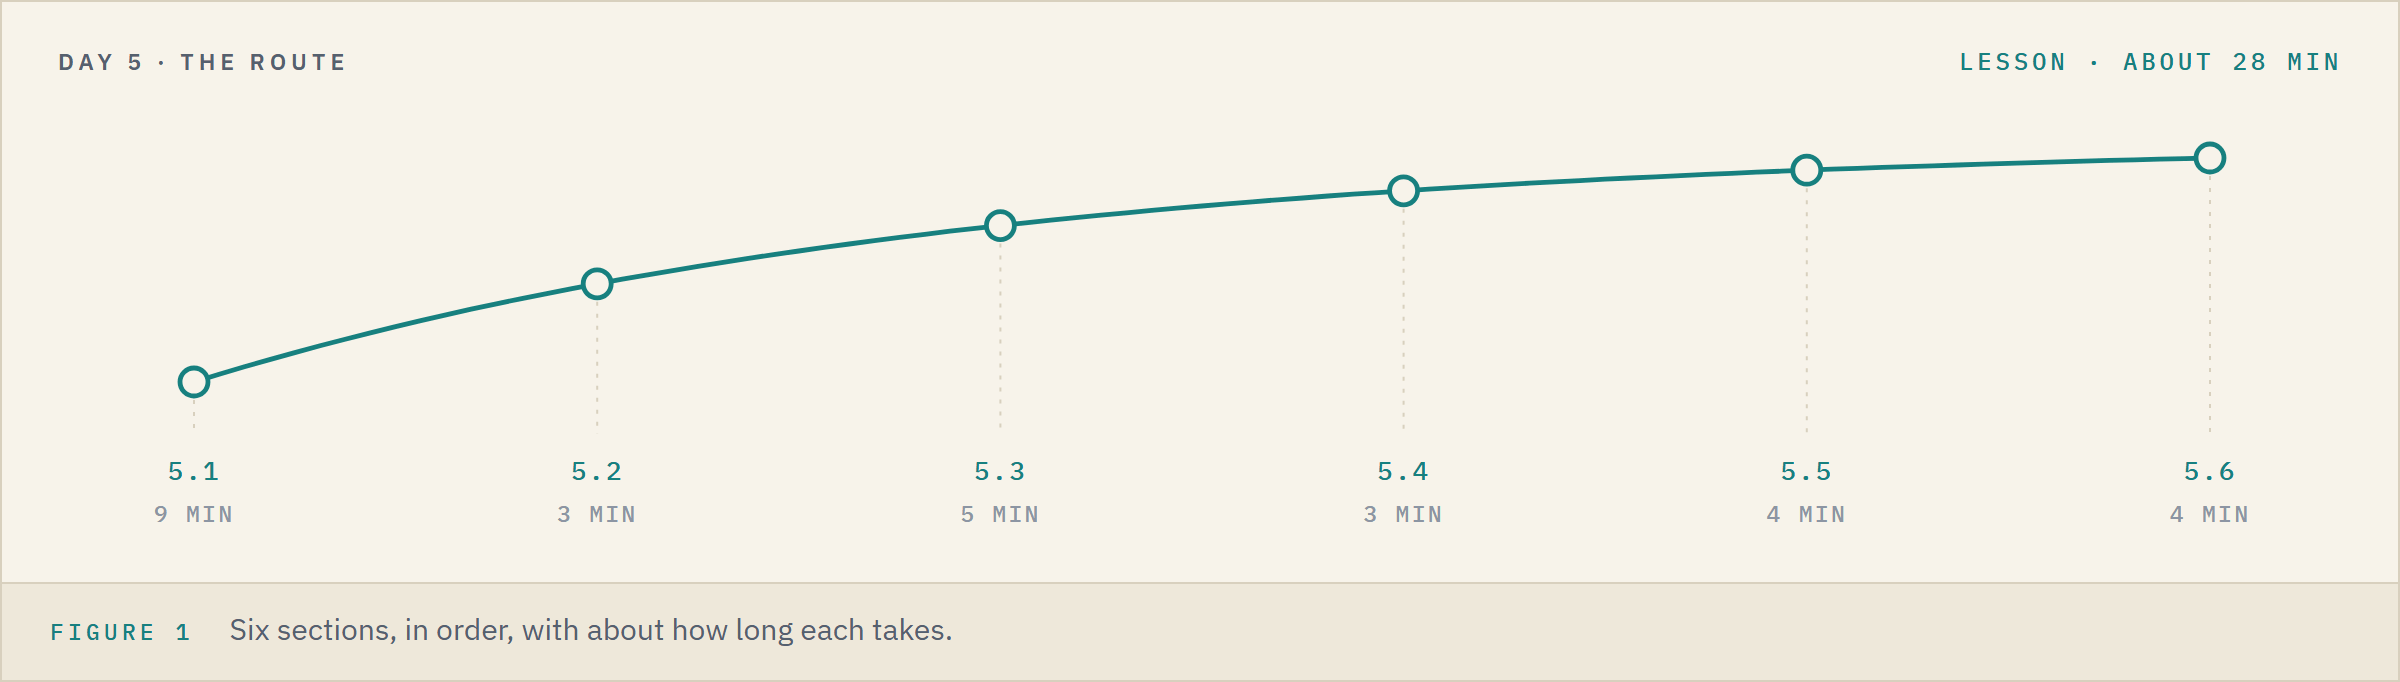

<table align="left">
<tr><th align="left"></th><th align="left">Section</th><th align="left">About</th></tr>
<tr><td align="left">5.1</td><td align="left">Yields From Re-offer Prices</td><td align="left">9 min</td></tr>
<tr><td align="left">5.2</td><td align="left">Prices at a Common Yield</td><td align="left">3 min</td></tr>
<tr><td align="left">5.3</td><td align="left">The Coupon That Prices Nearest Par on a 1/8 Grid</td><td align="left">5 min</td></tr>
<tr><td align="left">5.4</td><td align="left">The Price Effect of a 1/8 Coupon Step</td><td align="left">3 min</td></tr>
<tr><td align="left">5.5</td><td align="left">Two Rules Into the Test File, and the Week Tagged</td><td align="left">4 min</td></tr>
<tr><td align="left">5.6</td><td align="left">The Workbook for Excel</td><td align="left">4 min</td></tr>
</table>
<br clear="left">

**Time.** About 28 minutes for the lesson, then about 12 for the four exercises.

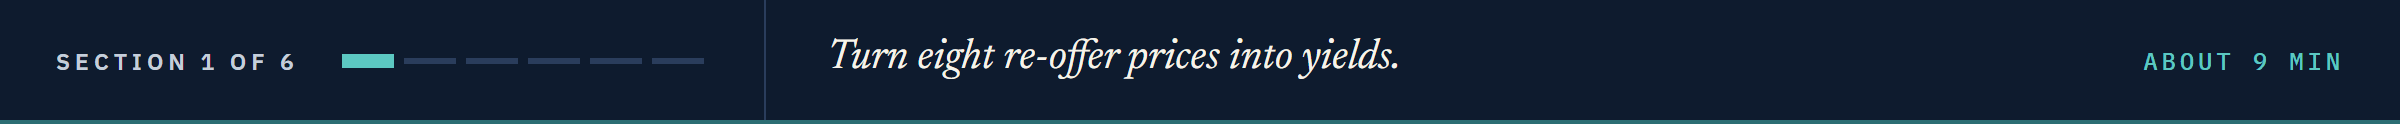

## 5.1 Yields From Re-offer Prices

### Today's Work Folder

Q. Where does today's work happen?

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module, its tests, and its Git history
# as notebook 04 left them.
# To start the day again, restart the kernel and run all cells.
work = start_day(5)

Work folder pfi_course2_05_k4w7q2xr: 2 data files, the module as notebook 04 left it, 4 commits


### The Module as Notebook 04 Left It

Q. How many tests pass this morning?

In [2]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

...........                                                              [100%]
11 passed in 0.50s



### Imports

Q. What does `yield_from_price` take, and in which units?

In [3]:
import importlib

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# the house greens and greys, as in Course 1's Visualization notebook
sns.set_theme(style='whitegrid', palette=['#2E7D5B', '#9AA5B1', '#1E4D3A', '#52606D'])
# the module the setup copied into the work folder
import bondmath
help(bondmath.yield_from_price)

Help on function yield_from_price in module bondmath:

yield_from_price(
    coupon_pct: float,
    price: float,
    years: float,
    frequency: int = 2
) -> float
    Yield of a bullet bond on a coupon date, from its price, by bisection.

    Units: coupon_pct in percent a year, price per 100 of face, years in years; the result is in percent.
    Convention: the yield, compounded `frequency` times a year, at which price_from_yield equals price.
    The search runs between -5 and 100 percent and stops when the bracket is narrower than 1e-10 percent.
    Raises ValueError if the price is outside the prices at those two yields.
    Excel: =RATE(frequency*years, coupon_pct/frequency, -price, 100)*frequency, then x 100.



### The Calendar, Typed

Q. Type the calendar in.

In [4]:
# the calendar as the desk typed it: coupons in percent, prices per 100 of face
calendar = pd.DataFrame({
    'cusip': ['99010KZA6', '99011LZA3', '99012MZA0', '99013NZA7',
              '99014OZA4', '99016QZA7', '99017RZA4', '99020UZA2'],
    'issuer': ['Thalostrin Finance', 'Galvostrin Resources', 'Hulvimer Pipeline',
               'Kezerone Paper', 'Elvorin Medical', 'Corvolvey Systems',
               'Rulvolvey Industrial', 'Morvithe Logistics'],
    'ticker': ['THAN', 'GALN', 'HULR', 'KEZE', 'ELVN', 'CORY', 'RULY', 'MORE'],
    'coupon_pct': [5.125, 5.625, 5.5, 4.625, 7.875, 7.0, 6.0, 8.75],
    'years': [5, 10, 7, 3, 8, 5, 30, 6],
    'maturity': ['2031-09-30', '2036-09-30', '2033-09-30', '2029-09-30',
                 '2034-09-30', '2031-09-30', '2056-09-30', '2032-09-30'],
    'reoffer_price': [99.874, 99.512, 99.76, 99.942, 100.0, 99.0, 98.975, 98.5],
})
print(len(calendar), 'issues typed')

8 issues typed


### Checked Before It Is Used

Q. Is every CUSIP different, and every coupon on the grid of eighths?

In [5]:
# is_unique, as in Course 1's First Look case study
assert calendar['cusip'].is_unique, 'two issues share a CUSIP'
# a coupon in eighths times 8 is a whole number, so % 1 (the part after the point) is 0
assert ((calendar['coupon_pct'] * 8) % 1 == 0).all(), 'a coupon is off the grid of eighths'
print('Eight different CUSIPs, every coupon a whole number of eighths')

Eight different CUSIPs, every coupon a whole number of eighths


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Count the different CUSIPs, A1:A8</td><td align="left"><code>calendar['cusip'].nunique()</code></td><td align="left"><code>=SUMPRODUCT(1/COUNTIF(A1:A8,A1:A8))</code></td><td align="left">8</td></tr>
<tr><td align="left">Coupon on the grid</td><td align="left"><code>(5.125 * 8) % 1</code></td><td align="left"><code>=MOD(5.125*8,1)</code></td><td align="left">0</td></tr>
</table>
<br clear="left">

### One Issue: Thalostrin

Q. What does Thalostrin yield at its re-offer price of 99.874?

In [6]:
# row 0 of the calendar, then the week's yield_from_price on its coupon, price, and years
thalostrin = calendar.iloc[0]
thalostrin_yield_pct = bondmath.yield_from_price(thalostrin['coupon_pct'],
                                                 thalostrin['reoffer_price'], thalostrin['years'])
print(f"Thalostrin yields {thalostrin_yield_pct:.4f} percent at {thalostrin['reoffer_price']}")

Thalostrin yields 5.1539 percent at 99.874


A little over its 5.125 coupon: a price under 100 means a yield over the coupon, as notebook 03 found.

### Predict 1: A Point Below Par, Five Years or Thirty

**Predict 1**

Corvolvey (7 percent, 5 years) and Rulvolvey (6 percent, 30 years) are both re-offered about a point below 100.
Corvolvey yields 24.2 bp over its coupon.

Q. How far over its coupon is Rulvolvey?

A) Near 4.0 bp: six times the term, a sixth of the gap.
B) Near 7.5 bp: the far years count for less.
C) Near 24.2 bp: the same discount, the same gap.

In [7]:
# each issue's row, its yield, and the yield's gap over the coupon in basis points
for ticker in ['CORY', 'RULY']:
    issue = calendar[calendar['ticker'] == ticker].iloc[0]
    issue_yield_pct = bondmath.yield_from_price(issue['coupon_pct'], issue['reoffer_price'],
                                                issue['years'])
    gap_bp = (issue_yield_pct - issue['coupon_pct']) * 100
    print(f"{ticker}, {issue['years']} years: yield {issue_yield_pct:.4f}, {gap_bp:.1f} bp over")

CORY, 5 years: yield 7.2420, 24.2 bp over
RULY, 30 years: yield 6.0747, 7.5 bp over


B.
The point of discount is earned over 30 years instead of 5, so each year gets less of it.
Not a sixth, though: the far years are discounted so hard they count for little.

### Predict 2: Eight Issues in One Call

**Predict 2**

Q. Hand the three whole columns to `yield_from_price` at once. What stops it?

A) An `if` in the module: it needs one True or False, and a column gives eight.
B) The `**` power: a whole column cannot be raised to a power.
C) The type hints: a column is not a `float`.

In [8]:
# three whole columns instead of three numbers
bondmath.yield_from_price(calendar['coupon_pct'], calendar['reoffer_price'], calendar['years'])

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

A.
`cash_flows` asks `if periods <= 0`, and eight periods give eight answers: Python will not guess whether you meant all of them or any.
So the module takes one bond at a time, like Excel's `YIELD`.

### Eight Issues, One at a Time

Q. What does every issue yield at its re-offer price?

In [9]:
# zip hands the function one issue's coupon, price, and years at a time
calendar['yield_pct'] = [bondmath.yield_from_price(c, p, t) for c, p, t in
                         zip(calendar['coupon_pct'], calendar['reoffer_price'], calendar['years'])]
calendar['gap_bp'] = (calendar['yield_pct'] - calendar['coupon_pct']) * 100
(calendar[['ticker', 'years', 'reoffer_price', 'yield_pct', 'gap_bp']].style
    .format({'reoffer_price': '{:.3f}', 'yield_pct': '{:.4f}', 'gap_bp': '{:.1f}'})
    .background_gradient(subset=['gap_bp'], cmap='Greens')
    .hide(axis='index'))

ticker,years,reoffer_price,yield_pct,gap_bp
THAN,5,99.874,5.1539,2.9
GALN,10,99.512,5.6897,6.5
HULR,7,99.760,5.5418,4.2
KEZE,3,99.942,4.6459,2.1
ELVN,8,100.000,7.8750,-0.0
CORY,5,99.000,7.2420,24.2
RULY,30,98.975,6.0747,7.5
MORE,6,98.500,9.0797,33.0


From 4.6459 percent (Kezerone, 3 years) to 9.0797 (Morvithe, 6 years), and 2.1 to 33.0 bp over the coupon.
Elvorin, at exactly 100, yields its coupon: its -0.0 is the search stopping a hair under 7.875.

### Excel's YIELD, Row by Row

Q. Does Excel's `YIELD` agree on all eight?

In [10]:
# Excel's YIELD of each re-offer price, from the reference file the setup copied
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv')
excel_yields = tvm[tvm['function'] == 'CALENDAR_YIELD'].head(8)
# YIELD returns a decimal, so times 100; to_numpy() drops the file's row labels
calendar['excel_yield_pct'] = (excel_yields['excel_value'] * 100).to_numpy()
largest_gap = (calendar['yield_pct'] - calendar['excel_yield_pct']).abs().max()
print(f'Largest gap to Excel: {largest_gap:.1e} percent')

Largest gap to Excel: 6.1e-09 percent


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Thalostrin's yield</td><td align="left"><code>bondmath.yield_from_price(5.125, 99.874, 5)</code></td><td align="left"><code>=YIELD(DATE(2026,9,30),DATE(2031,9,30),5.125/100,99.874,100,2,0)</code></td><td align="left">0.0515390782041645</td></tr>
</table>
<br clear="left">

`YIELD` takes the coupon as a decimal and returns one: times 100 for percent.

### The Gap Over the Coupon, by Term

Q. Draw each gap, shortest term first.

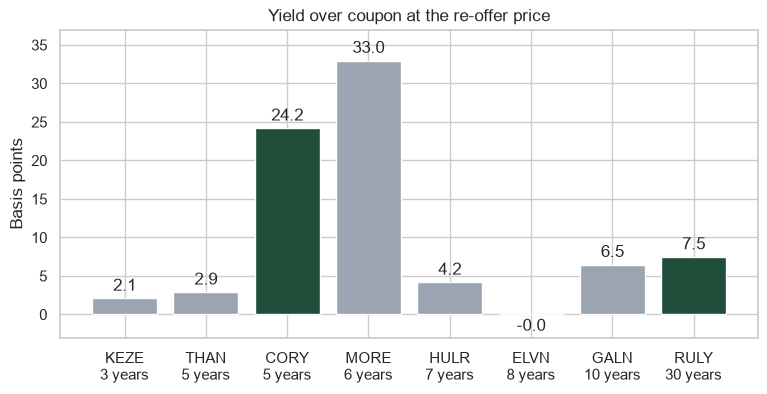

In [11]:
# shortest term first; the two issues of Predict 1 in dark green
by_term = calendar.sort_values('years')
labels = [f'{ticker}\n{years} years' for ticker, years in zip(by_term['ticker'], by_term['years'])]
colours = ['#1E4D3A' if t in ['CORY', 'RULY'] else '#9AA5B1' for t in by_term['ticker']]
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, by_term['gap_bp'], color=colours)
ax.bar_label(bars, fmt='%.1f', padding=3)
ax.set_ylim(-3, 37)
ax.set_title('Yield over coupon at the re-offer price')
ax.set_ylabel('Basis points')
plt.show()

**Eight yields, each within 6.1e-09 percent of Excel. Now take credit out: one yield for all.**

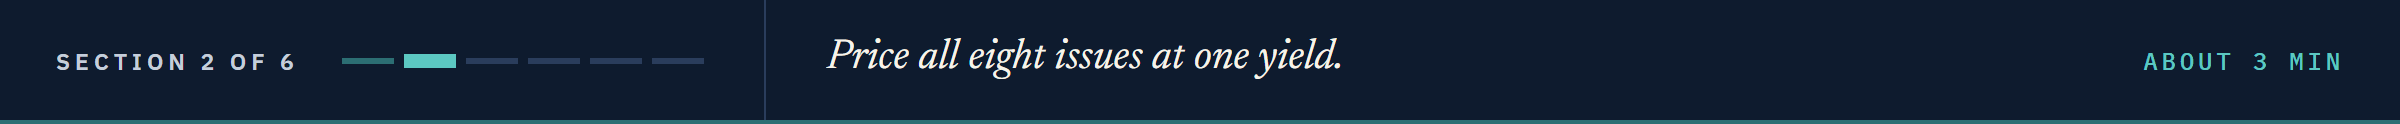

## 5.2 Prices at a Common Yield

Each yield mixes the issuer's credit with the bond's term.
Price all eight at one round yield, 5.50 percent, a what-if and not a market level, and only coupon and term are left.
A coupon above 5.50 then prices over 100, one below it under 100 (notebook 03).

### Predict 3: Five Years or Thirty, at 5.50

**Predict 3**

Q. Corvolvey pays 7 percent for 5 years, Rulvolvey 6 percent for 30. At 5.50 percent, whose price is higher?

A) Rulvolvey: its extra coupon lasts six times longer.
B) Corvolvey: a full point more coupon.
C) The same: one yield, one price.

In [12]:
# one yield for every issue: a round what-if, not a market level
common_yield_pct = 5.5
for ticker in ['CORY', 'RULY']:
    issue = calendar[calendar['ticker'] == ticker].iloc[0]
    price = bondmath.price_from_yield(issue['coupon_pct'], common_yield_pct, issue['years'])
    print(f"{ticker}: {issue['coupon_pct']} percent for {issue['years']} years, price {price:.4f}")

CORY: 7.0 percent for 5 years, price 106.4801
RULY: 6.0 percent for 30 years, price 107.3057


A.
Corvolvey pays 0.750 a half-year over 5.50 percent for 10 half-years; Rulvolvey 0.250 for 60.
The premium is the value today of those extras (notebook 03), and the small long one is worth more.

### All Eight at 5.50 Percent

Q. Price every issue at 5.50 percent. Does Excel's `PRICE` agree?

In [13]:
calendar['price_at_5_50'] = [bondmath.price_from_yield(c, common_yield_pct, t)
                             for c, t in zip(calendar['coupon_pct'], calendar['years'])]
# Excel's PRICE of each issue at 5.50 percent: the first eight CALENDAR_PRICE rows
excel_prices = tvm[tvm['function'] == 'CALENDAR_PRICE'].head(8)
calendar['excel_price_at_5_50'] = excel_prices['excel_value'].to_numpy()
largest_gap = (calendar['price_at_5_50'] - calendar['excel_price_at_5_50']).abs().max()
print(f'Largest gap to Excel: {largest_gap:.1e} per 100 of face')

Largest gap to Excel: 1.1e-13 per 100 of face


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Rulvolvey at 5.50</td><td align="left"><code>bondmath.price_from_yield(6.0, 5.5, 30)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2056,9,30),6/100,5.5/100,100,2,0)</code></td><td align="left">107.30566550271652</td></tr>
<tr><td align="left">Corvolvey at 5.50</td><td align="left"><code>bondmath.price_from_yield(7.0, 5.5, 5)</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2031,9,30),7/100,5.5/100,100,2,0)</code></td><td align="left">106.4800571225415</td></tr>
</table>
<br clear="left">

### Distance From Par

Q. How far from 100 is each price, shortest term first?

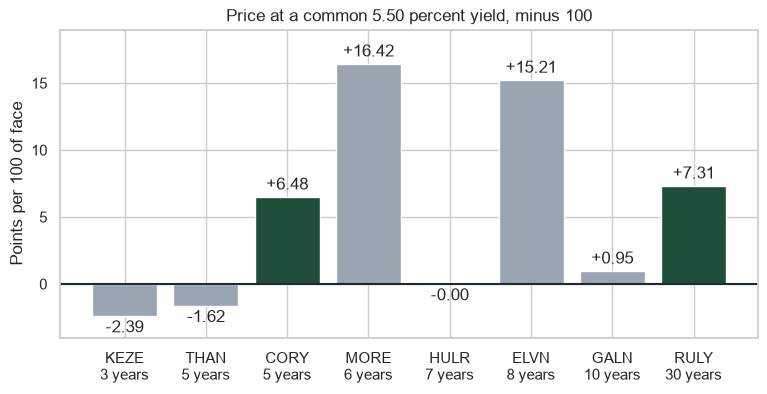

In [14]:
# the calendar again, shortest term first, with the first chart's labels and colours
by_term = calendar.sort_values('years')
fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, by_term['price_at_5_50'] - 100, color=colours)
# '%+.2f' writes the sign: + above par, - below
ax.bar_label(bars, fmt='%+.2f', padding=3)
# par is the zero line
ax.axhline(0, color='#1F2933')
ax.set_ylim(-4, 19)
ax.set_title('Price at a common 5.50 percent yield, minus 100')
ax.set_ylabel('Points per 100 of face')
plt.show()

Hulvimer's -0.00 is a rounding error in the last digits: its price is 100.

**Five above 100, Thalostrin and Kezerone below, Hulvimer at 100: a small premium paid long outweighs a large one paid short. Next, the coupon that lands at par.**

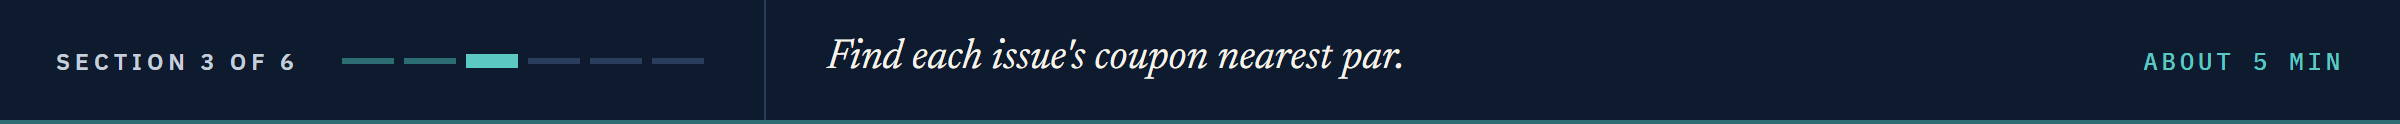

## 5.3 The Coupon That Prices Nearest Par on a 1/8 Grid

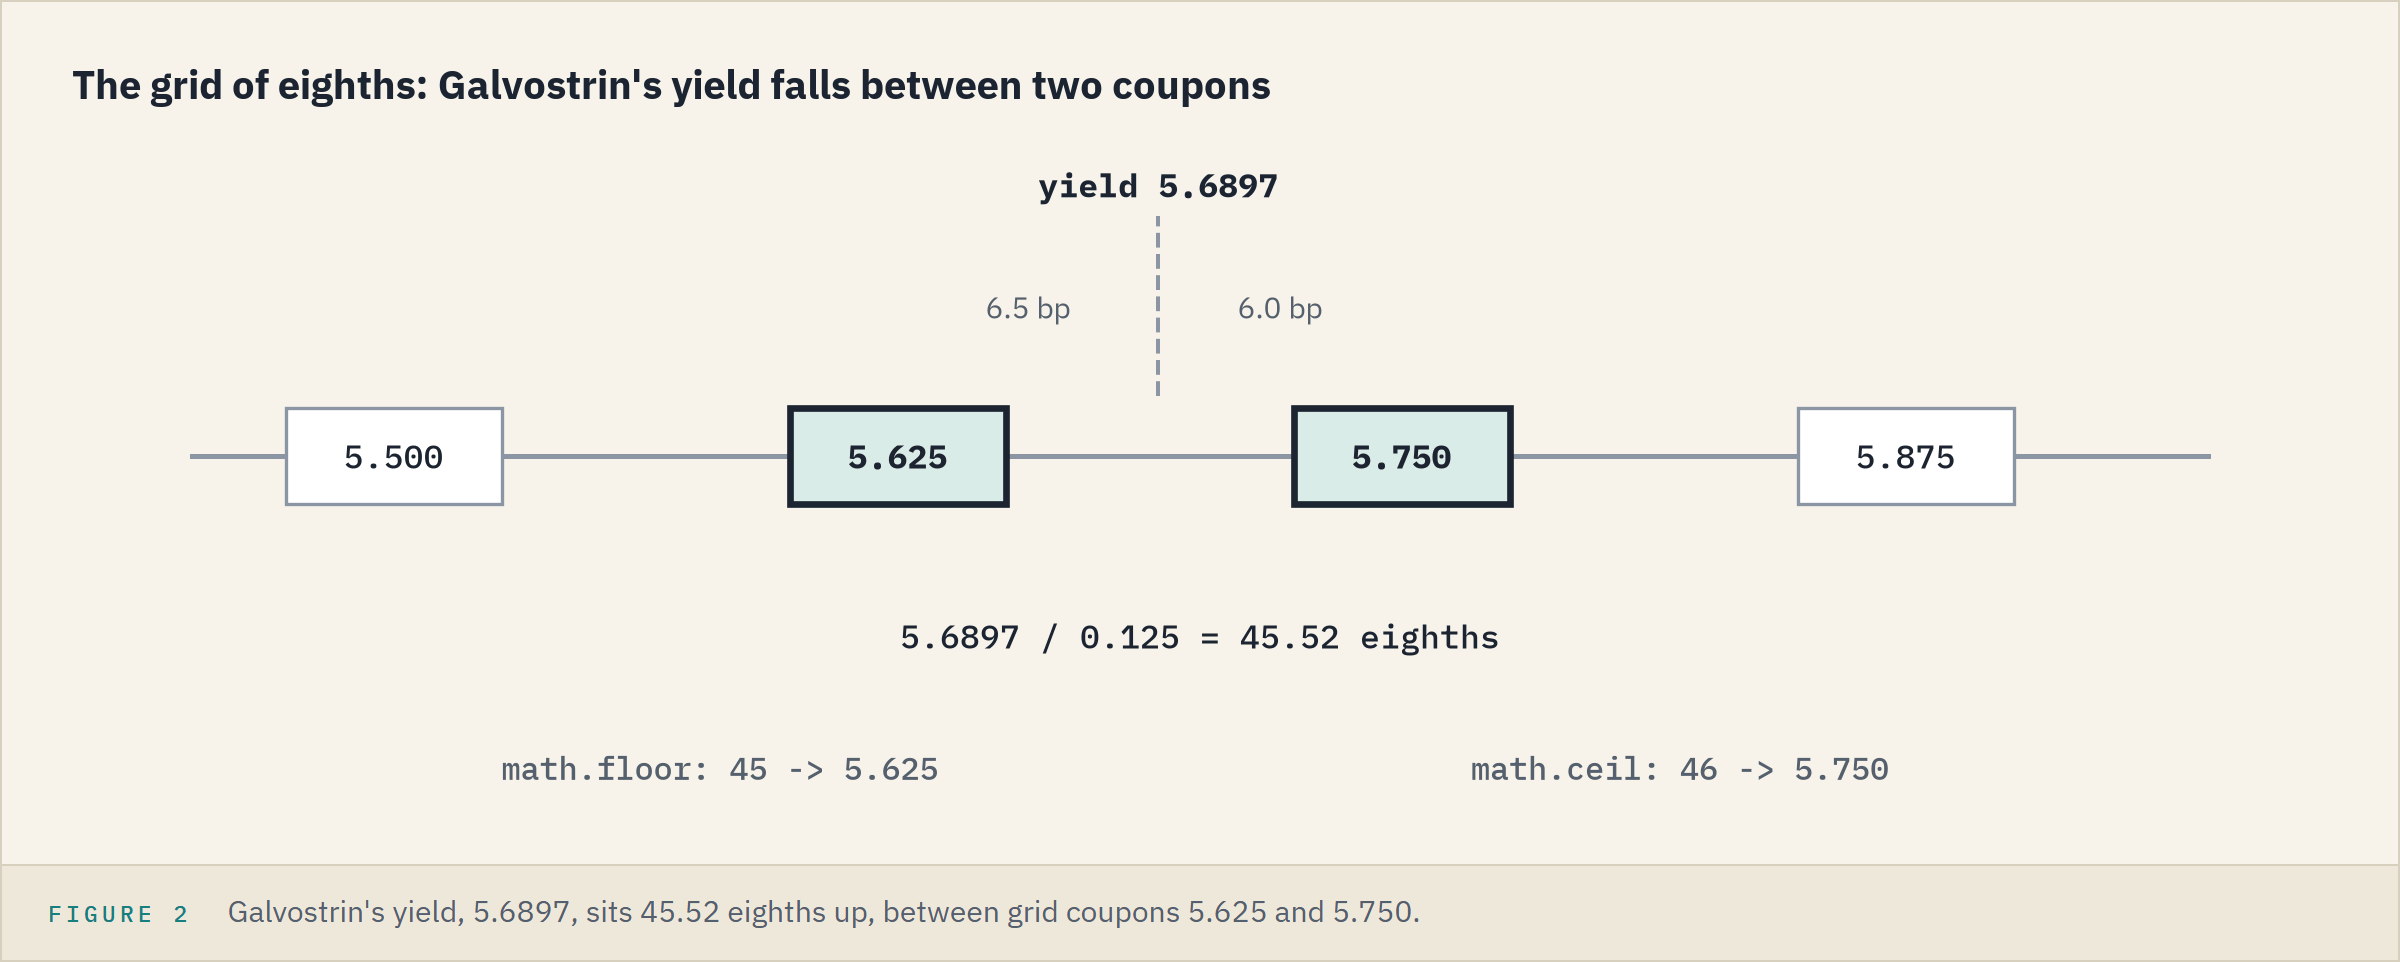

Coupons are set in eighths: 5.500, 5.625, 5.750, and so on.
A coupon equal to the yield prices at 100 (notebook 03), but a yield is rarely a whole number of eighths.
So take the two grid coupons either side of the yield, and keep the one that prices nearer 100.

### Rounding to the Grid

Q. Which grid coupons sit either side of Galvostrin's yield?

In [15]:
import math

galvostrin = calendar[calendar['ticker'] == 'GALN'].iloc[0]
# the yield counted in eighths; math.floor rounds down to a whole number, math.ceil rounds up
eighths = galvostrin['yield_pct'] / 0.125
low_coupon, high_coupon = math.floor(eighths) * 0.125, math.ceil(eighths) * 0.125
print(f"{galvostrin['yield_pct']:.4f} percent is {eighths:.2f} eighths:",
      f'{low_coupon} or {high_coupon}')

5.6897 percent is 45.52 eighths: 5.625 or 5.75


### Predict 4: Galvostrin's Two Grid Coupons

**Predict 4**

Q. On Galvostrin's 10-year term, at its own yield, which coupon prices nearer 100?

A) 5.625, the calendar's coupon.
B) 5.750, the grid coupon nearer the yield.
C) Both equally near.

In [16]:
# price each grid coupon at Galvostrin's own yield, then its distance from 100
for coupon_pct in [low_coupon, high_coupon]:
    price = bondmath.price_from_yield(coupon_pct, galvostrin['yield_pct'], galvostrin['years'])
    print(f'Coupon {coupon_pct:.3f}: price {price:.4f}, {abs(price - 100):.4f} from 100')

Coupon 5.625: price 99.5120, 0.4880 from 100
Coupon 5.750: price 100.4553, 0.4553 from 100


B, by 0.0327.

### Price Against Coupon

Q. What does the price do as the coupon steps along the grid?

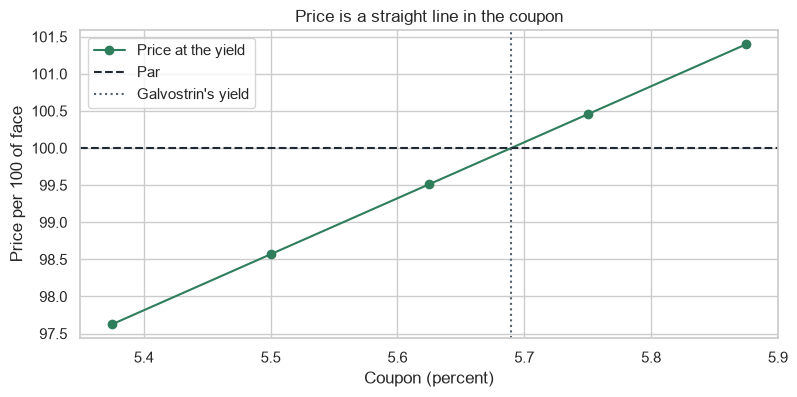

In [17]:
# five grid coupons around the yield, each priced at Galvostrin's yield
grid = [5.375, 5.5, 5.625, 5.75, 5.875]
grid_prices = [bondmath.price_from_yield(c, galvostrin['yield_pct'], 10) for c in grid]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(grid, grid_prices, marker='o', label='Price at the yield')
ax.axhline(100, color='#1F2933', linestyle='--', label='Par')
ax.axvline(galvostrin['yield_pct'], color='#52606D', linestyle=':', label="Galvostrin's yield")
ax.set_title('Price is a straight line in the coupon')
ax.set_xlabel('Coupon (percent)')
ax.set_ylabel('Price per 100 of face')
ax.legend()
plt.show()

**Price is a straight line in the coupon.**
Each eighth adds the same amount, and the line crosses 100 at the yield.
So the grid coupon nearest the yield is the one nearest par.

### The Grid Coupon for Every Issue

Q. Turn the two-coupon test into a function.

In [18]:
def nearest_par_coupon(yield_pct, years):
    """The grid coupon either side of yield_pct whose price at yield_pct is nearer 100."""
    eighths = yield_pct / 0.125
    candidates = [math.floor(eighths) * 0.125, math.ceil(eighths) * 0.125]
    # each candidate's distance from 100, priced at the yield
    distances = [abs(bondmath.price_from_yield(c, yield_pct, years) - 100) for c in candidates]
    return candidates[distances.index(min(distances))]


print(nearest_par_coupon(galvostrin['yield_pct'], 10))

5.75


Q. Which coupon prices each issue nearest par, and how many eighths up is it?

In [19]:
calendar['par_coupon_pct'] = [nearest_par_coupon(y, t) for y, t in
                              zip(calendar['yield_pct'], calendar['years'])]
# eighths between the calendar's coupon and the one nearest par
calendar['eighths_up'] = ((calendar['par_coupon_pct'] - calendar['coupon_pct']) / 0.125).round()
(calendar[['ticker', 'coupon_pct', 'yield_pct', 'par_coupon_pct', 'eighths_up']].style
    .format({'coupon_pct': '{:.3f}', 'yield_pct': '{:.4f}', 'par_coupon_pct': '{:.3f}',
             'eighths_up': '{:.0f}'})
    .background_gradient(subset=['eighths_up'], cmap='Greens')
    .hide(axis='index'))

ticker,coupon_pct,yield_pct,par_coupon_pct,eighths_up
THAN,5.125,5.1539,5.125,0
GALN,5.625,5.6897,5.750,1
HULR,5.500,5.5418,5.500,0
KEZE,4.625,4.6459,4.625,0
ELVN,7.875,7.8750,7.875,0
CORY,7.000,7.2420,7.250,2
RULY,6.000,6.0747,6.125,1
MORE,8.750,9.0797,9.125,3


**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Round down to the grid</td><td align="left"><code>math.floor(5.69 / 0.125) * 0.125</code></td><td align="left"><code>=FLOOR(5.69,0.125)</code></td><td align="left">5.625</td></tr>
<tr><td align="left">Round up to the grid</td><td align="left"><code>math.ceil(5.69 / 0.125) * 0.125</code></td><td align="left"><code>=CEILING(5.69,0.125)</code></td><td align="left">5.75</td></tr>
<tr><td align="left">Nearest grid coupon</td><td align="left"><code>nearest_par_coupon(5.6897, 10)</code></td><td align="left"><code>=MROUND(5.69,0.125)</code></td><td align="left">5.75</td></tr>
</table>
<br clear="left">

`MROUND` only rounds, so the yield stays in percent, and a yield exactly halfway goes up.

**Four issues already hold the coupon nearest par; Galvostrin and Rulvolvey sit one eighth short, Corvolvey two, Morvithe three. Next: what an eighth is worth.**

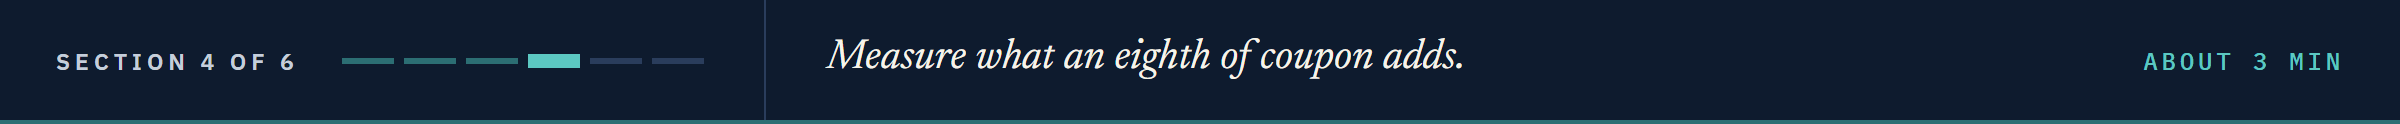

## 5.4 The Price Effect of a 1/8 Coupon Step

### Predict 5: An Eighth on a Thirty-Year Bond

**Predict 5**

Rulvolvey at 5.50 percent, with a coupon of 6.125 instead of 6.000.
An eighth a year for 30 years would be 3.75, but each payment is discounted.

Q. How much does the price rise, per 100? Write down a number.

In [20]:
# the same bond priced twice at 5.50: its own coupon, then one eighth more
price_now = bondmath.price_from_yield(6.0, common_yield_pct, 30)
price_stepped = bondmath.price_from_yield(6.125, common_yield_pct, 30)
print(f'One eighth of coupon adds {price_stepped - price_now:.4f} per 100 of face')

One eighth of coupon adds 1.8264 per 100 of face


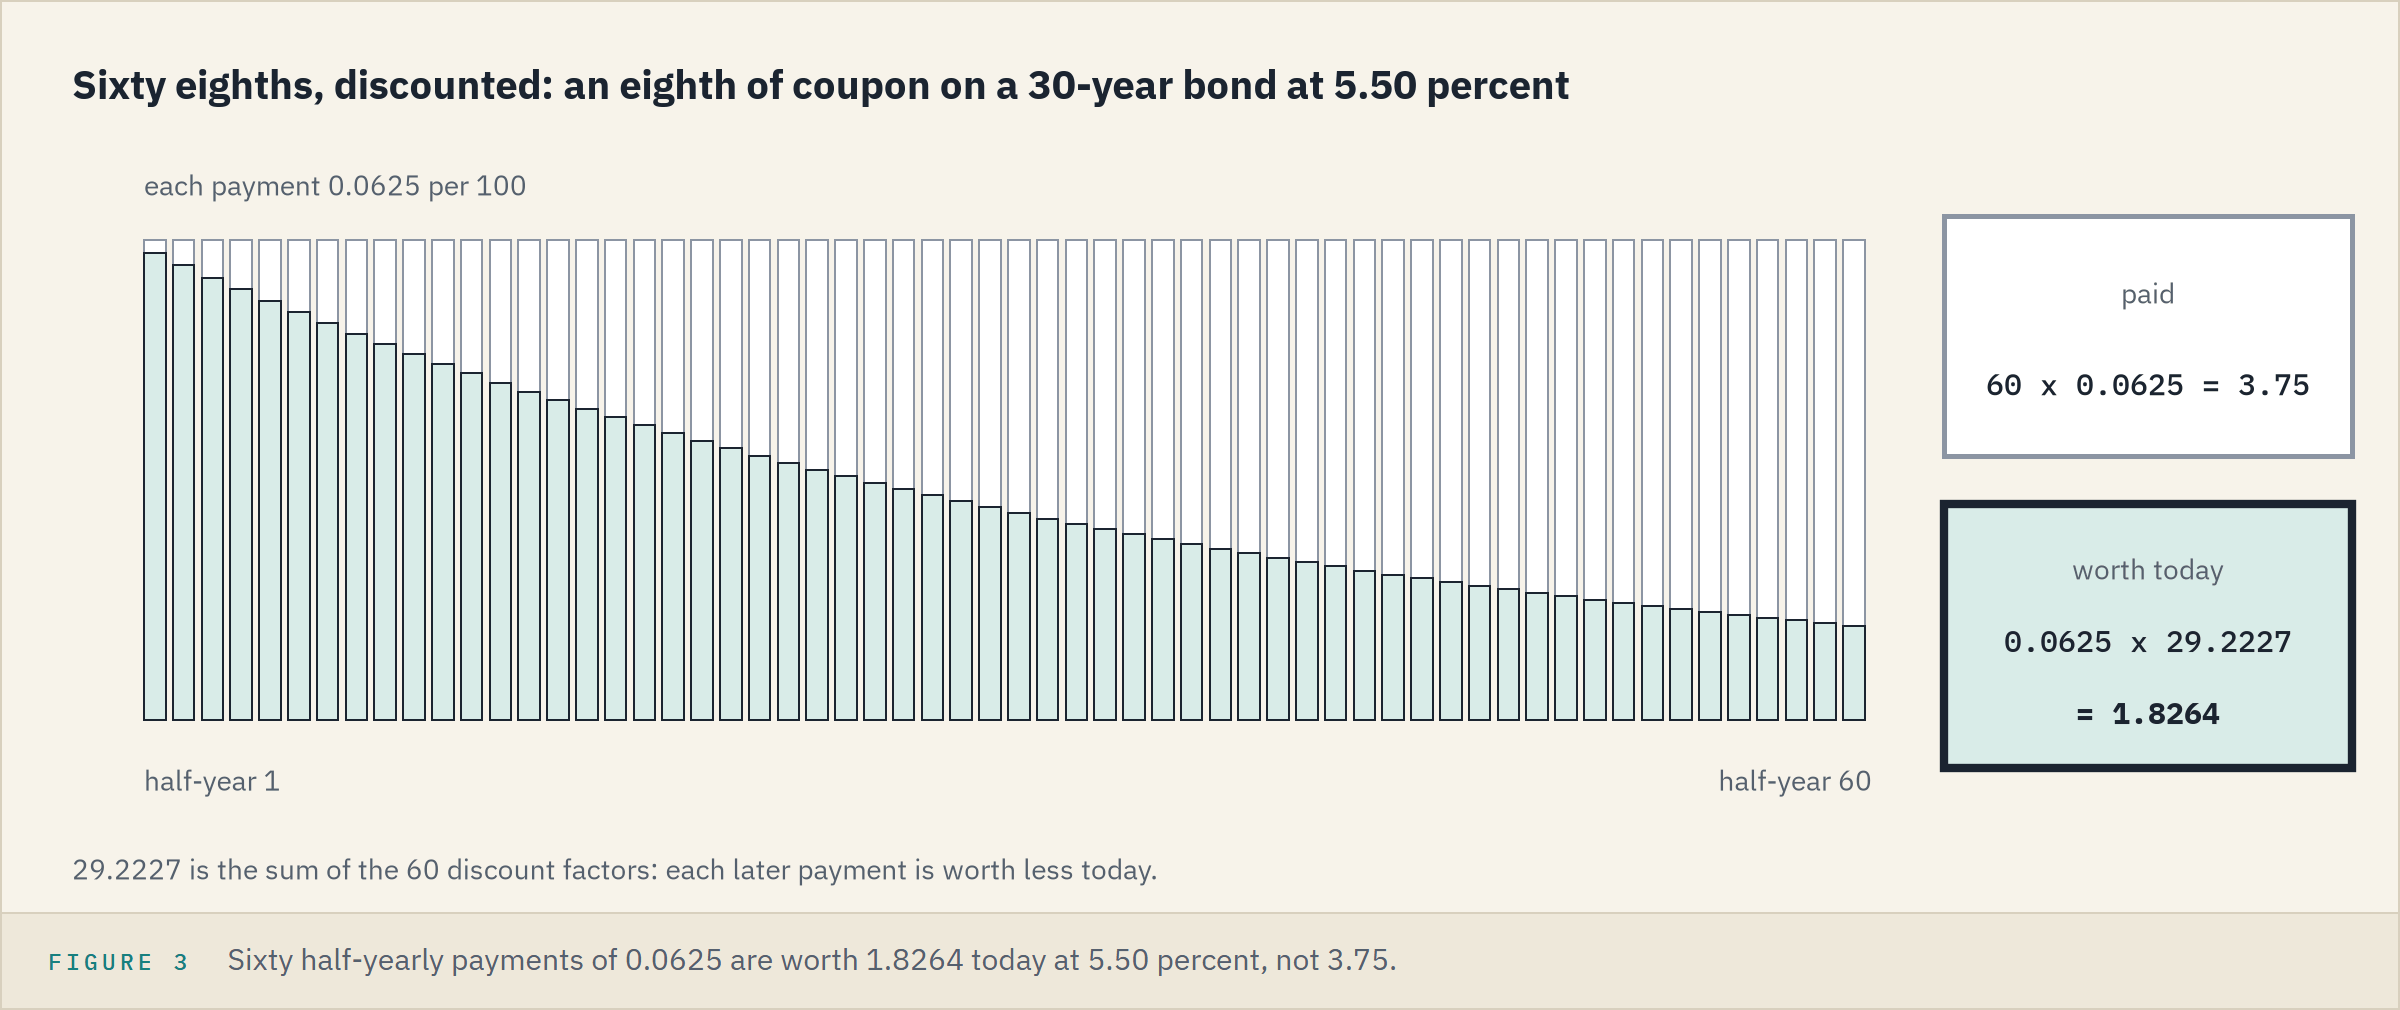

1.8264, under half of 3.75.
The 60 discount factors at 5.50 percent add up to 29.2227, not 60.

### An Eighth on Every Issue

Q. What is an eighth worth on each issue, and does Excel agree?

In [21]:
calendar['step_value'] = [bondmath.price_from_yield(c + 0.125, common_yield_pct, t)
                          - bondmath.price_from_yield(c, common_yield_pct, t)
                          for c, t in zip(calendar['coupon_pct'], calendar['years'])]
# the last eight CALENDAR_PRICE rows: each issue at 5.50 with its coupon an eighth higher
excel_stepped = tvm[tvm['function'] == 'CALENDAR_PRICE'].tail(8)['excel_value'].to_numpy()
excel_steps = excel_stepped - calendar['excel_price_at_5_50']
print(f"Largest gap to Excel: {(calendar['step_value'] - excel_steps).abs().max():.1e}")

Largest gap to Excel: 2.8e-14


### What an Eighth Is Worth, by Term

Q. Draw each step against the term, beside "an eighth a year".

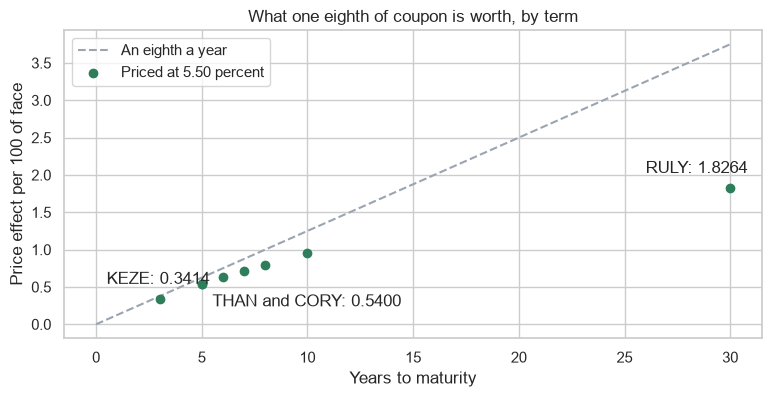

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
# an eighth a year, undiscounted: 3.75 at 30 years
ax.plot([0, 30], [0, 0.125 * 30], linestyle='--', color='#9AA5B1', label='An eighth a year')
ax.scatter(calendar['years'], calendar['step_value'], zorder=3, label='Priced at 5.50 percent')
# three labels, each with its distance from its dot
labels_at = {'KEZE': ('KEZE', -2.5, 0.2), 'THAN': ('THAN and CORY', 0.5, -0.3),
             'RULY': ('RULY', -4, 0.2)}
for ticker, years, step in zip(calendar['ticker'], calendar['years'], calendar['step_value']):
    if ticker in labels_at:
        name, dx, dy = labels_at[ticker]
        ax.text(years + dx, step + dy, f'{name}: {step:.4f}')
ax.set_title('What one eighth of coupon is worth, by term')
ax.set_xlabel('Years to maturity')
ax.set_ylabel('Price effect per 100 of face')
ax.legend()
plt.show()

Thalostrin and Corvolvey, both 5 years, share one dot although their coupons are almost two points apart: on a straight line the step does not depend on the coupon.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">An eighth on Rulvolvey</td><td align="left"><code>price_stepped - price_now</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),DATE(2056,9,30),6.125/100,5.5/100,100,2,0)-PRICE(DATE(2026,9,30),DATE(2056,9,30),6/100,5.5/100,100,2,0)</code></td><td align="left">1.826416</td></tr>
<tr><td align="left">The extra coupons alone</td><td align="left"><code>0.0625</code> times the 60 discount factors</td><td align="left"><code>=-PV(5.5/100/2,2*30,0.125/2,0)</code></td><td align="left">1.826416</td></tr>
</table>
<br clear="left">

**0.3414 to 1.8264 per 100: the longer the bond, the bigger the step, and always under an eighth a year.**

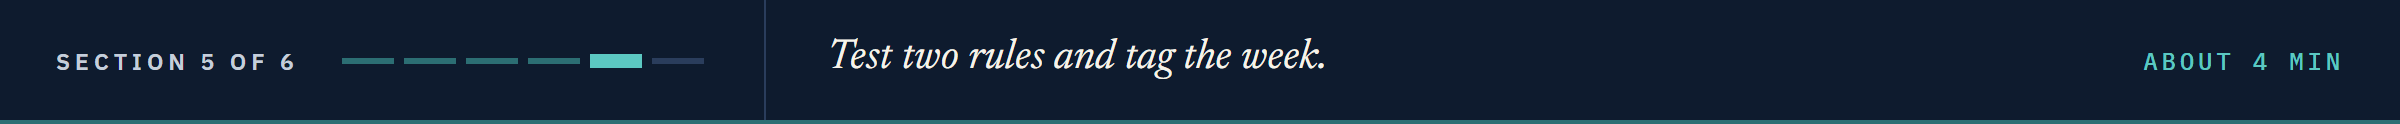

## 5.5 Two Rules Into the Test File, and the Week Tagged

### Two Rules Every Bond Obeys

Two facts carried the case: a coupon equal to the yield prices at 100 (5.3), and price falls as yield rises (notebook 03, behind every yield in 5.1).
They hold for every bond, so they go in the test file.

Q. Add the two tests.

In [23]:
%%writefile -a test_bondmath.py


def test_par_bond_prices_at_100():
    # a coupon equal to the yield prices at 100 for every frequency and term
    for frequency in (1, 2, 4):
        for years in (1, 2, 5, 10, 30):
            assert bondmath.price_from_yield(5.5, 5.5, years, frequency) == pytest.approx(100, abs=1e-9)


def test_price_falls_as_yield_rises():
    # price a 10-year 6 percent bond at yields from 2 to 12 percent
    prices = [bondmath.price_from_yield(6.0, yield_pct, 10, 2) for yield_pct in (2, 4, 6, 8, 10, 12)]
    # every price is below the one before it
    for earlier, later in zip(prices, prices[1:]):
        assert later < earlier

Appending to test_bondmath.py


The first prices fifteen par bonds: five terms at three frequencies.
In the second, `prices[1:]` is the list without its first price, so `zip` pairs each price with the next.

### Run the Tests

Q. Do all the tests pass?

In [24]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

.............                                                            [100%]
13 passed in 0.50s



### What Changed

Q. Which lines changed today?

In [25]:
# what Git sees, as in notebook 04, then the lines changed in each file, as in notebook 02
!git -C "{work}" status --short
!git -C "{work}" diff --stat

 M test_bondmath.py
?? __pycache__/
 test_bondmath.py | 15 +++++++++++++++
 1 file changed, 15 insertions(+)


Only the test file changed, by 15 added lines; `bondmath.py` is untouched, and `__pycache__` waits for notebook 06.

### Commit

Q. Commit with a subject that says what and a body that says why.

In [26]:
subject = 'Notebook 05: tests of par pricing and of price against yield'
body = 'The new issue calendar relied on both rules; the tests pin them down before week 2.'
# {subject} and {body} put the two texts into the ! line
!git -C "{work}" add test_bondmath.py
!git -C "{work}" commit -q -m "{subject}" -m "{body}"

### Tag the Week

Q. Name the commit that ends week 1.

In [27]:
# a tag is a name fixed to one commit; --decorate shows the names beside the hashes
!git -C "{work}" tag week1
!git -C "{work}" log --oneline --decorate

0a77531 (HEAD -> main, tag: week1) Notebook 05: tests of par pricing and of price against yield
7147a11 Notebook 04: yield_from_price
3f57cac Notebook 03: convert_yield
408a678 Notebook 02: cash_flows and price_from_yield
d029474 Notebook 01: future_value and present_value


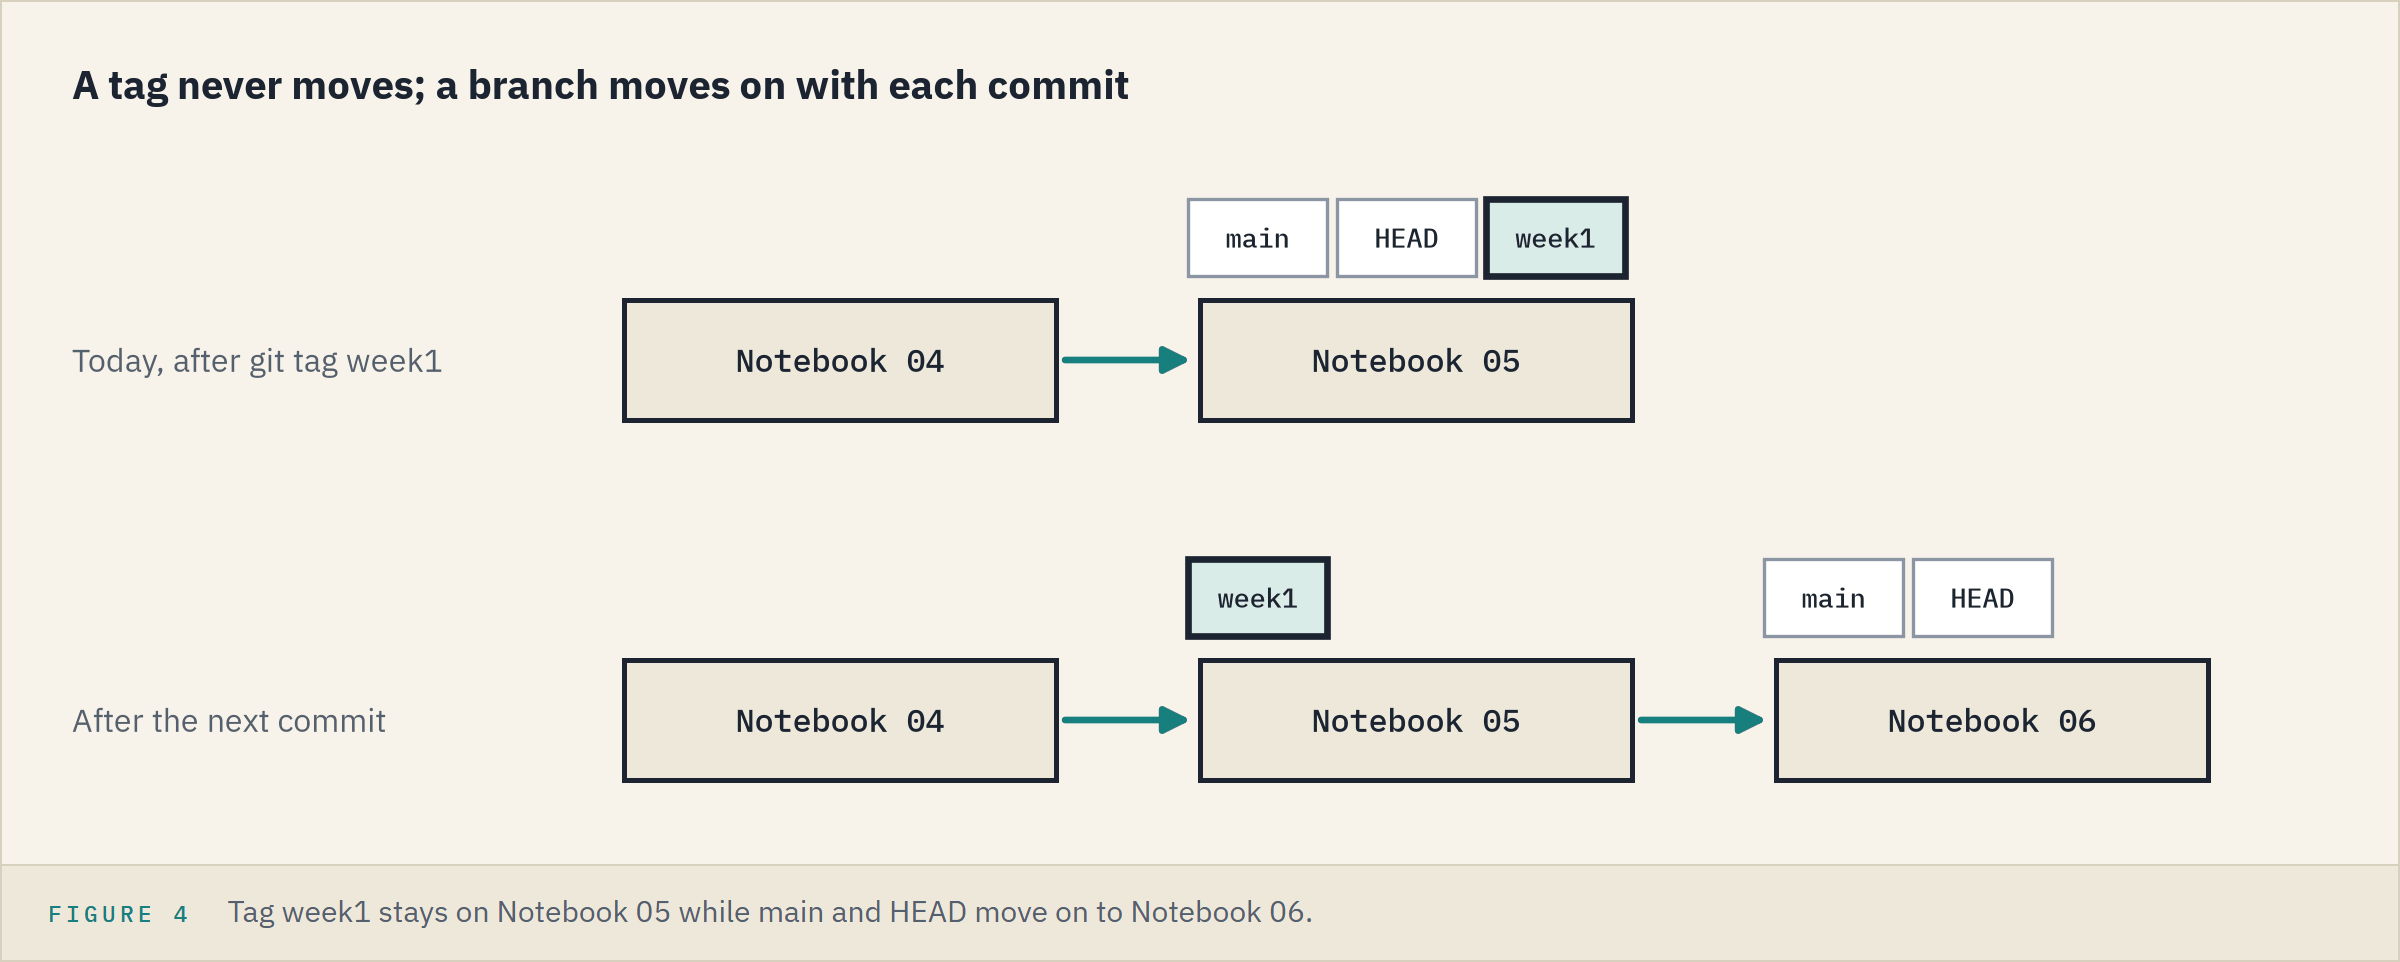

A new commit moves `main` on; `week1` stays where it is.
In Excel terms, it is a copy saved as `calendar_week1.xlsx` while the live file moves on.

**13 tests pass and `week1` marks the module as the week ends. Last ask: the workbook.**

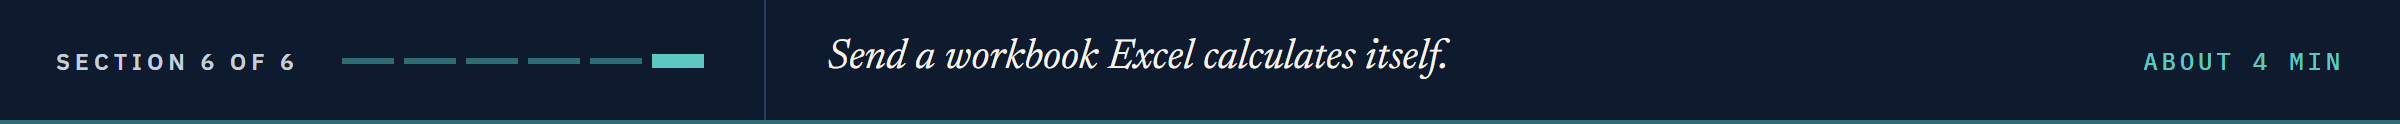

## 5.6 The Workbook for Excel

Course 1's `to_excel` writes a table to a workbook, and a text that starts with `=` goes in as an Excel formula.
So the yield and price columns can be live `YIELD` and `PRICE`, beside Python's numbers.

### Formulas Into a Workbook

Q. Build the sheet: the inputs, Python's numbers, and a formula for each Excel column.

In [28]:
sheet = calendar[['cusip', 'issuer', 'coupon_pct', 'maturity', 'reoffer_price',
                  'yield_pct']].copy()
# a real date, so YIELD and PRICE can read column D
sheet['maturity'] = pd.to_datetime(sheet['maturity'])
# rows 2 to 9 of the sheet: each formula reads its own row's coupon, maturity, and price
rows = range(2, 10)
sheet['excel_yield_pct'] = [f'=YIELD(DATE(2026,9,30),D{r},C{r}/100,E{r},100,2,0)*100'
                            for r in rows]
sheet['yield_gap'] = [f'=G{r}-F{r}' for r in rows]
sheet['price_at_5_50'] = calendar['price_at_5_50']
sheet['excel_price_at_5_50'] = [f'=PRICE(DATE(2026,9,30),D{r},C{r}/100,5.5/100,100,2,0)'
                                for r in rows]
sheet['price_gap'] = [f'=J{r}-I{r}' for r in rows]
print(sheet.loc[0, 'excel_yield_pct'])

=YIELD(DATE(2026,9,30),D2,C2/100,E2,100,2,0)*100


### Save It

Q. Save the workbook in the work folder.

In [29]:
# no folder in the name, so the file goes into the work folder; engine='openpyxl' names
# the library that writes it, the one this course installs, so Colab writes the same file
sheet.to_excel('new_issue_calendar.xlsx', index=False, engine='openpyxl')
# in Python text, \\ is one backslash
print(f'Open it from PowerShell: Invoke-Item "$env:TEMP\\{work.name}\\new_issue_calendar.xlsx"')

Open it from PowerShell: Invoke-Item "$env:TEMP\pfi_course2_05_k4w7q2xr\new_issue_calendar.xlsx"


### Predict 6: Reading It Back With pandas

**Predict 6**

Q. `pd.read_excel` reads the saved workbook back. What does its `excel_yield_pct` column hold?

A) The yields.
B) The formula text, starting with `=`.
C) Nothing: empty cells.

In [30]:
back = pd.read_excel('new_issue_calendar.xlsx')
back[['cusip', 'yield_pct', 'excel_yield_pct', 'price_at_5_50', 'excel_price_at_5_50']].head(3)

,cusip,yield_pct,excel_yield_pct,price_at_5_50,excel_price_at_5_50
0,99010KZA6,5.153908,NaN,98.379986,NaN
1,99011LZA3,5.689665,NaN,100.951703,NaN
2,99012MZA0,5.541832,NaN,100.000000,NaN


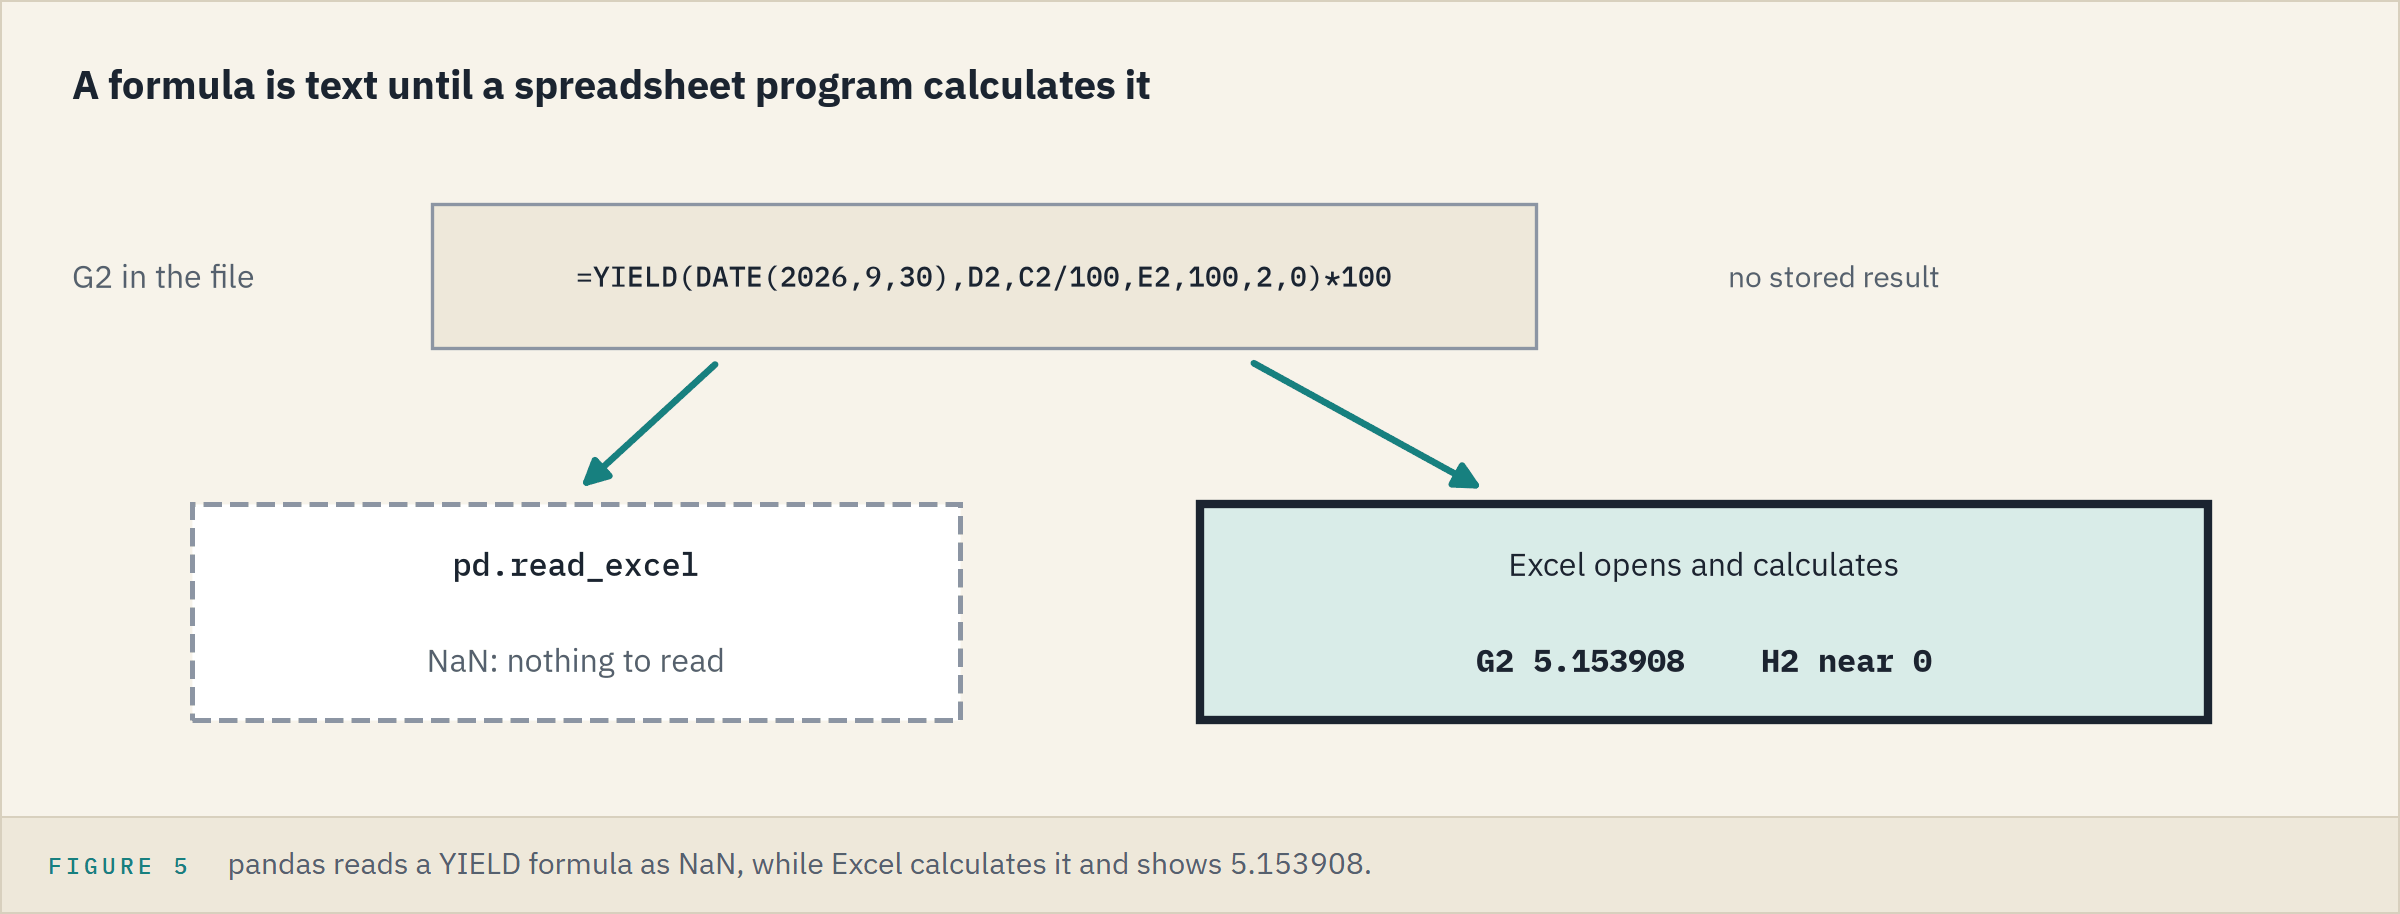

C: `NaN` in every formula column.
pandas writes a formula's text and no result; only a spreadsheet program calculates it.

### What Excel Shows


Opened in Excel for Microsoft 365, the workbook shows every value at once: the file asks for a full calculation on opening.

**Excel side by side.**

<table align="left">
<tr><th align="left">Job</th><th align="left">Python</th><th align="left">Excel</th><th align="left">Result</th></tr>
<tr><td align="left">Yield, row 2</td><td align="left"><code>yield_pct</code></td><td align="left"><code>=YIELD(DATE(2026,9,30),D2,C2/100,E2,100,2,0)*100</code></td><td align="left">5.153908</td></tr>
<tr><td align="left">Price at 5.50, row 2</td><td align="left"><code>price_at_5_50</code></td><td align="left"><code>=PRICE(DATE(2026,9,30),D2,C2/100,5.5/100,100,2,0)</code></td><td align="left">98.379986</td></tr>
<tr><td align="left">Largest yield gap</td><td align="left"><code>yield_gap</code></td><td align="left"><code>=G4-F4</code></td><td align="left">-6.1E-09</td></tr>
<tr><td align="left">Largest price gap</td><td align="left"><code>price_gap</code></td><td align="left"><code>=K8</code>, from <code>=J8-I8</code></td><td align="left">1.3E-13</td></tr>
</table>
<br clear="left">

Change a re-offer price in column E, and its yield and gap change with it.
Run the PowerShell line the save cell printed; in Colab, download the file and choose Enable Editing if Excel opens it in Protected View.

**Excel calculated the file itself and agreed to 6.1e-09 percent. The note is answered.**

## Summary

The checks behind every answer:

<table align="left">
<tr><th align="left">Check</th><th align="left">Result</th></tr>
<tr><td align="left">Calendar typed</td><td align="left">8 issues, 8 CUSIPs, coupons on the grid</td></tr>
<tr><td align="left"><code>yield_from_price</code> against <code>YIELD</code>, 8 rows</td><td align="left">within 6.1e-09 percent</td></tr>
<tr><td align="left"><code>price_from_yield</code> against <code>PRICE</code> at 5.50, 8 rows</td><td align="left">within 1.1e-13</td></tr>
<tr><td align="left">Eighth steps against <code>PRICE</code>, 8 rows</td><td align="left">within 2.8e-14</td></tr>
<tr><td align="left">pytest</td><td align="left">13 passed</td></tr>
<tr><td align="left">Workbook opened in Excel</td><td align="left">gaps at most 6.1e-09 percent and 1.3e-13</td></tr>
</table>
<br clear="left">

## Bring It Home

Copy the work folder's two files into your own folder, then test, commit, and tag there.
In a PowerShell terminal in VS Code, with the course's `.venv` active, use the work folder name your setup cell printed:

```powershell
Set-Location "$HOME\projects\my_bondmath"
$work = "$env:TEMP\pfi_course2_05_k4w7q2xr"
Copy-Item "$work\bondmath.py", "$work\test_bondmath.py" .
python -m pytest -q
git add bondmath.py test_bondmath.py
git commit -m "Notebook 05: tests of par pricing and of price against yield"
git tag week1
```

The copy replaces your two files, so anything of your own goes into the work folder first.
In Colab, download the two files from the file browser instead.
The work folder stays in your temp folder until you delete it.

## You Can Now

By the end of this notebook, you can:

* Turn a calendar of re-offer prices into yields, one bond at a time.
* Price a set of bonds at one common yield, and say why a long small premium can outweigh a short large one.
* Find the coupon on the grid of eighths that prices nearest par.
* Measure what an eighth of coupon is worth, and say why it is under an eighth a year.
* Write a workbook of live `YIELD` and `PRICE` formulas, and say why pandas reads them back empty.
* Name a commit with `git tag`, and read the names with `git log --oneline --decorate`.

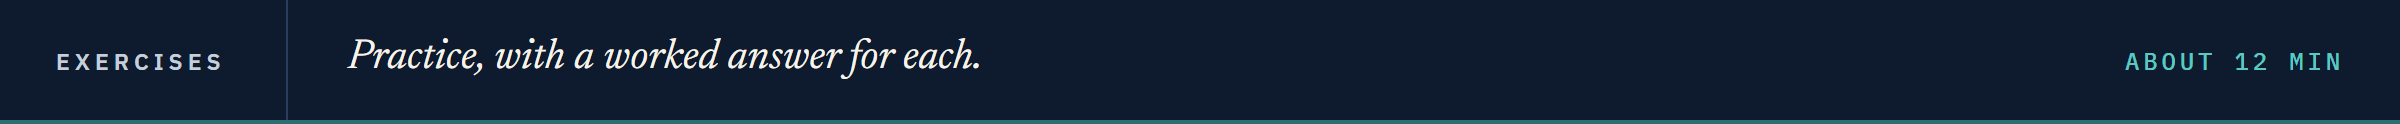

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

Five more invented new issues, settling on 30 September 2026 like the first eight.
Replace each `...` with your code, then run the check cell under it.
Run the next two cells first.

In [31]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [32]:
exercise_calendar = pd.DataFrame({
    'ticker': ['FESA', 'KRIN', 'DRAA', 'VYRE', 'NEVR'],
    'issuer': ['Feskundra Systems', 'Krilorin Logistics', 'Dralundra Brands', 'Vyrerone Metals',
               'Nevovar Energy'],
    'coupon_pct': [4.5, 6.25, 4.25, 7.25, 6.125],
    'years': [4, 7, 2, 8, 12],
    'reoffer_price': [99.85, 99.375, 100.0, 99.0, 99.625],
})
exercise_calendar

,ticker,issuer,coupon_pct,years,reoffer_price
0,FESA,Feskundra Systems,4.500,4,99.850
1,KRIN,Krilorin Logistics,6.250,7,99.375
2,DRAA,Dralundra Brands,4.250,2,100.000
3,VYRE,Vyrerone Metals,7.250,8,99.000
4,NEVR,Nevovar Energy,6.125,12,99.625


### Exercise 1

Q. Find each issue's yield at its re-offer price and its gap over the coupon in bp. Store Nevovar's yield in percent, unrounded, in **ex1_nevovar**, and the ticker furthest over its coupon in **ex1_widest**.

In [33]:
ex1_nevovar = ...
ex1_widest = ...

In [34]:
check('Exercise 1 Nevovar yield', ex1_nevovar, 6.169691301427065)
check('Exercise 1 furthest over its coupon', ex1_widest, 'VYRE')

Exercise 1 Nevovar yield: not attempted yet
Exercise 1 furthest over its coupon: not attempted yet


### Exercise 2

Q. Price every issue at 5.50 percent, and find what an eighth more coupon adds to each price. Store Krilorin's price in **ex2_krilorin** and Nevovar's eighth in **ex2_step_nevovar**, per 100 of face, unrounded.

In [35]:
ex2_krilorin = ...
ex2_step_nevovar = ...

In [36]:
check('Exercise 2 Krilorin at 5.50', ex2_krilorin, 104.30912805092527)
check('Exercise 2 Nevovar step', ex2_step_nevovar, 1.0875497936428076)

Exercise 2 Krilorin at 5.50: not attempted yet
Exercise 2 Nevovar step: not attempted yet


### Exercise 3

Q. Add `par_coupon_pct(yield_pct, step=0.125)` to your module: the grid coupon nearest the yield, a tie going up as Excel's `MROUND` does, and a `ValueError` for a yield or step of zero or below. Docstring first. Test it against `=MROUND(yield,0.125)`: 5.43 gives 5.375, 5.69 gives 5.75, 9.08 gives 9.125, 4.55 gives 4.5, and the ties 5.0625 gives 5.125 and 4.9375 gives 5.0; and a yield of 0 raises `ValueError`. Run pytest, reload, and store the grid coupon of each Exercise 1 yield, in order, in **ex3_coupons**.

In [37]:
%%writefile -a bondmath.py


# Exercise 3: write par_coupon_pct(yield_pct, step=0.125) below this line

Appending to bondmath.py


In [38]:
%%writefile -a test_bondmath.py


# Exercise 3: write test_par_coupon_pct_matches_excel_mround() below this line

Appending to test_bondmath.py


In [39]:
# run pytest, reload the module, then call your function
ex3_coupons = ...

In [40]:
check('Exercise 3 grid coupons', ex3_coupons, [4.5, 6.375, 4.25, 7.375, 6.125])

Exercise 3 grid coupons: not attempted yet


### Exercise 4: AI check

You gave an AI assistant `price_from_yield`'s docstring as the request: the docstring is the prompt.
This came back, written for this course in the style of an assistant's answer.

In [41]:
# written for this course in the style of an AI assistant's answer.
# It runs, and it contains one bug.
def assistant_price_from_yield(coupon_pct, yield_pct, years, frequency=2):
    """Price of a bullet bond on a coupon date, from its yield.

    Units: coupon_pct and yield_pct in percent a year, years in years, price per 100 of face.
    Convention: each cash flow is discounted at yield_pct compounded `frequency` times a year.
    On a coupon date there is no accrued interest, so this is both the clean and the dirty price.
    Excel: =-PV(yield_pct/100/frequency, frequency*years, coupon_pct/frequency, 100)
    """
    # the yield and the coupon for one period, both as decimals
    period_yield = yield_pct / 100 / frequency
    period_coupon = coupon_pct / 100 / frequency
    periods = round(years * frequency)
    price = 0.0
    for k in range(1, periods + 1):
        # each coupon, and the face back with the last one
        amount = period_coupon + 1 if k == periods else period_coupon
        price += amount / (1 + period_yield) ** k
    return price

Q. What should Rulvolvey, 6 percent for 30 years, be at 5.50 percent? Section 5.2 has it. Run the function.

In [42]:
print(f'Rulvolvey at 5.50 from the assistant: {assistant_price_from_yield(6.0, 5.5, 30):.6f}')

Rulvolvey at 5.50 from the assistant: 1.073057


Q. Test it against every `CALENDAR_PRICE` row before you trust it.

In [43]:
tvm = pd.read_csv('bondmath_excel_reference_tvm.csv')
rows = tvm[tvm['function'] == 'CALENDAR_PRICE']
# each row: Excel's PRICE of one issue at rate_pct, per 100 of face
for case, c, y, t, excel in zip(rows['case_id'], rows['coupon_pct'], rows['rate_pct'],
                                rows['years'], rows['excel_value']):
    result = assistant_price_from_yield(c, y, t)
    assert abs(result - excel) < 1e-6, f'{case}: {result:.6f} against Excel {excel:.6f}'
print(f'All {len(rows)} CALENDAR_PRICE rows match Excel')

AssertionError: tvm_calendar_price_01: 0.983800 against Excel 98.379986

Q. Fix the convention the function broke and run the test again. Store `assistant_price_from_yield(6.0, 5.5, 30)` in **ex4_rulvolvey** and the rows checked in **ex4_rows**.

In [44]:
ex4_rulvolvey = ...
ex4_rows = ...

In [45]:
check('Exercise 4 Rulvolvey', ex4_rulvolvey, 107.30566550271652)
check('Exercise 4 rows checked', ex4_rows, 21)

Exercise 4 Rulvolvey: not attempted yet
Exercise 4 rows checked: not attempted yet


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Yield at re-offer</td><td align="left">4.6459 percent (Kezerone) to 9.0797 (Morvithe); 2.1 to 33.0 bp over the coupon, Elvorin at par</td></tr>
<tr><td align="left">One yield for all</td><td align="left">At 5.50, five above 100, two below, Hulvimer at 100; Rulvolvey 107.3057 over Corvolvey 106.4801</td></tr>
<tr><td align="left">Coupon nearest par</td><td align="left">The grid coupon nearest the yield: their own on four, one to three eighths up on the rest</td></tr>
<tr><td align="left">An eighth's worth</td><td align="left">0.3414 to 1.8264 per 100 at 5.50</td></tr>
<tr><td align="left">A workbook Excel calculates</td><td align="left"><code>new_issue_calendar.xlsx</code>, live <code>YIELD</code> and <code>PRICE</code>, gaps at most 6.1e-09 percent</td></tr>
</table>
<br clear="left">

Be proud: week 1's module prices and yields any bullet bond on a coupon date, and Excel agrees with every number.

Next, Dates and Coupon Schedules (notebook 06) lets a bond settle between two coupon dates.

[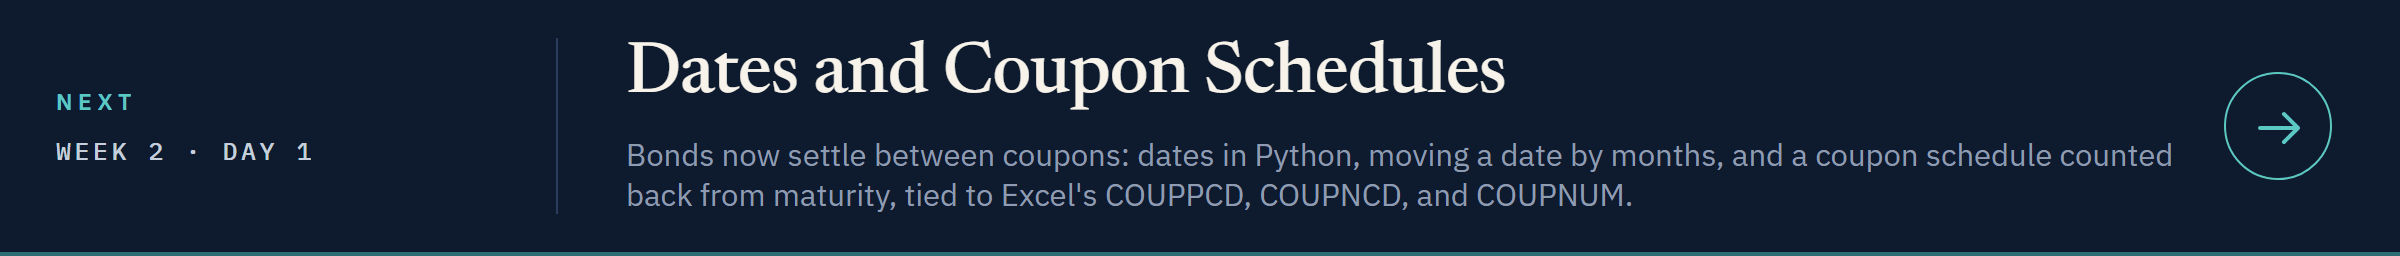](../../week2/day1/06_dates_and_coupon_schedules.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week2/day1/06_dates_and_coupon_schedules.ipynb)